# 1. QQQ Daily RSI(2) Mean Reversion - Hypothesis Definition & Baseline Backtest
## Systematic Trading Approach following TIS Framework

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **TIS RSI(2) Mean Reversion** strategy on **Invesco QQQ Trust (QQQ)** daily bars.

### 1.1 Core Quantitative Hypothesis
The strategy exploits a structural property of equity index markets identified in our Exploratory Data Analysis:
- **Macro Trend Drift**: The Nasdaq-100 exhibits a persistent multi-decade upward drift (~10.9% CAGR since 1999).
- **Short-Term Micro Reversal**: Daily returns exhibit negative autocorrelation (Lag 1 ACF = -0.058) and a sub-diffusive Hurst exponent ($H = 0.48 < 0.50$).
- **The Core Premise**: When an asset in a macro bull market (`Close > SMA(200)`) experiences severe, sudden selling pressure (`RSI(2) < 15`), institutional liquidity providers step in to absorb retail stop-losses and panics. The resulting bounce generates an asymmetric, high-probability mean-reverting edge over the subsequent 2 to 5 sessions.

### 1.2 Frozen Strategy Rules
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | Invesco QQQ Trust (`QQQ`), Daily bars (split/dividend adjusted) |
| **Trend Filter** | `Close[t-1] > SMA(200)[t-1]` (evaluated at day $t-1$ close) |
| **Entry Trigger** | `RSI(2)[t-1] < 15` (Wilder smoothing, evaluated at day $t-1$ close) |
| **Execution** | Buy at **OPEN** of day $t$ with slippage cost: `Entry = Open[t] * (1 + 0.0005)` |
| **Exit Trigger** | Two consecutive green candles: `Close[t-1] > Open[t-1]` AND `Close[t-2] > Open[t-2]` |
| **Exit Execution** | Sell at **OPEN** of day $t$ with slippage cost: `Exit = Open[t] * (1 - 0.0005)` |
| **Direction** | Long only, no price stop loss |
| **Trading Costs** | 5 bps per side (0.05% per side = 10 bps round-trip), zero commission |
| **Position Sizing** | (a) **Capital Sizing**: 100% equity per trade<br>(b) **ATR Risk Sizing**: 1% risk per trade with 2x ATR(14) stop, capped at 100% |

### 1.3 Provenance & Adaptation
- **Academic / Practitioner Origin**: Developed by Larry Connors & Cesar Alvarez (*Short Term Trading Strategies That Work*, 2008).
- **TIS Refinement**: Trade It Simple (TIS) adapted the exit logic from a fixed MA(5) cross to an agile two-consecutive-green-candles price-action exit, increasing trade velocity and reducing overnight drawdown exposure.

## 2. IMPORTS AND CONFIG

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add utils directory to system path
utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
sys.path.insert(0, os.path.abspath('.'))

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
import rsi2_engine as eng

print("Imports complete.")
print(f"Loaded utils from: {utils_path}")

Imports complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE SPLIT

In [2]:
# Download QQQ daily data from Yahoo Finance
df_raw = eng.load_qqq(start="1999-01-01")
df = eng.prepare(df_raw, sma_len=200)

# In-Sample / Out-of-Sample Split (70% IS / 30% OOS matching TIS framework)
n_is = int(len(df) * 0.70)
df_is = df.iloc[:n_is].copy()
df_oos = df.iloc[n_is:].copy()

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min().strftime('%Y-%m-%d')} to {df.index.max().strftime('%Y-%m-%d')})")
print(f"In-Sample (IS, 70%): {len(df_is):,} bars ({df_is.index.min().strftime('%Y-%m-%d')} to {df_is.index.max().strftime('%Y-%m-%d')})")
print(f"Out-of-Sample (OOS, 30%): {len(df_oos):,} bars ({df_oos.index.min().strftime('%Y-%m-%d')} to {df_oos.index.max().strftime('%Y-%m-%d')})")
print("=" * 70)

df.head()

DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 6,735 (1999-12-21 to 2026-10-01)
In-Sample (IS, 70%): 4,714 bars (1999-12-21 to 2018-09-14)
Out-of-Sample (OOS, 30%): 2,021 bars (2018-09-17 to 2026-10-01)


,open,high,low,close,volume,sma,rsi2,green,ma5,atr14
time,,,,,,,,,,
1999-12-21,71.654626,75.284706,71.246900,75.284706,26003800,50.590214,99.164999,1,71.081190,1.938860
1999-12-22,75.074317,75.179537,73.601240,75.048012,22313600,50.750543,90.269797,0,72.443791,1.920618
1999-12-23,75.646460,76.389575,74.916497,75.942390,17543600,50.914291,94.200939,1,73.648566,1.888651
1999-12-27,76.021300,76.047605,73.995819,75.495201,19281800,51.081065,67.094001,0,74.642897,1.900303
1999-12-28,75.547774,76.179092,74.548186,75.021675,15346400,51.239420,41.688640,0,75.358397,1.881061


## 4. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 5 BPS SLIPPAGE PER SIDE)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,Sharpe,Max Drawdown
0,In-Sample (1999-2018),100% Capital,194,66.5%,1.990,0.560%,182.1%,0.55,-17.73%
1,In-Sample (1999-2018),1% ATR Risk,194,66.5%,1.990,0.190%,45.5%,0.62,-6.68%
2,Out-of-Sample (2018-2026),100% Capital,93,79.6%,2.681,0.789%,102.8%,0.88,-11.73%
3,Out-of-Sample (2018-2026),1% ATR Risk,93,79.6%,2.309,0.230%,23.9%,0.77,-4.66%
4,Full Period (1999-2026),100% Capital,287,70.7%,2.189,0.635%,474.1%,0.64,-17.73%
5,Full Period (1999-2026),1% ATR Risk,287,70.7%,2.090,0.204%,80.6%,0.67,-6.68%


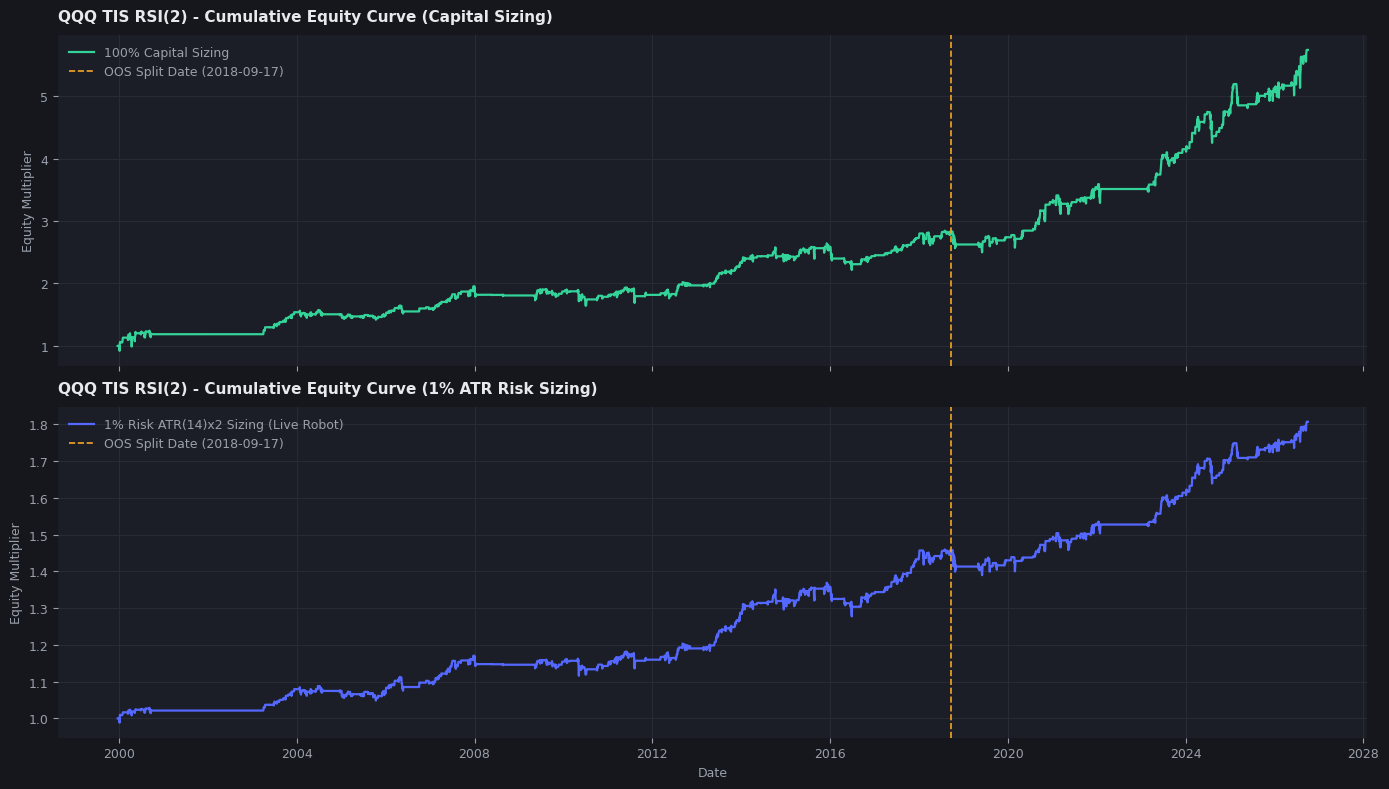

In [3]:
# Run backtest with frozen rules across IS, OOS, and Full Dataset
trades_is = eng.run_rsi2_backtest(df_is, rsi_thr=15.0, sma_len=200, exit_mode="2green", slip_pct_per_side=0.05)
trades_oos = eng.run_rsi2_backtest(df_oos, rsi_thr=15.0, sma_len=200, exit_mode="2green", slip_pct_per_side=0.05)
trades_all = eng.run_rsi2_backtest(df, rsi_thr=15.0, sma_len=200, exit_mode="2green", slip_pct_per_side=0.05)

def format_perf_table(t_df, period_name, price_df):
    m_cap = compute_metrics(t_df, contract_multiplier=1.0, cost_per_trade=0.0)
    t_atr = t_df.assign(pnl=t_df['pnl_atr'], win=t_df['pnl_atr'] > 0)
    m_atr = compute_metrics(t_atr, contract_multiplier=1.0, cost_per_trade=0.0)
    
    ret_cap = eng.daily_returns(price_df, t_df, sizing="capital")
    ret_atr = eng.daily_returns(price_df, t_df, sizing="atr")
    
    eq_cap = (1.0 + ret_cap).cumprod()
    eq_atr = (1.0 + ret_atr).cumprod()
    
    return pd.DataFrame([
        {
            'Period': period_name,
            'Sizing': '100% Capital',
            'Trades': m_cap['num_trades'],
            'Win Rate': f"{m_cap['win_rate']:.1f}%",
            'Profit Factor': f"{m_cap['profit_factor']:.3f}",
            'Expectancy': f"{m_cap['expectancy']:.3f}%",
            'Total Return': f"{(eq_cap.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_cap):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_cap)*100:.2f}%"
        },
        {
            'Period': period_name,
            'Sizing': '1% ATR Risk',
            'Trades': m_atr['num_trades'],
            'Win Rate': f"{m_atr['win_rate']:.1f}%",
            'Profit Factor': f"{m_atr['profit_factor']:.3f}",
            'Expectancy': f"{m_atr['expectancy']:.3f}%",
            'Total Return': f"{(eq_atr.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_atr):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_atr)*100:.2f}%"
        }
    ])

perf_table = pd.concat([
    format_perf_table(trades_is, 'In-Sample (1999-2018)', df_is),
    format_perf_table(trades_oos, 'Out-of-Sample (2018-2026)', df_oos),
    format_perf_table(trades_all, 'Full Period (1999-2026)', df)
], ignore_index=True)

print("=" * 80)
print("PERFORMANCE SUMMARY (NET OF 5 BPS SLIPPAGE PER SIDE)")
print("=" * 80)
display(perf_table)

# Plot Equity Curves
ret_cap_all = eng.daily_returns(df, trades_all, sizing="capital")
ret_atr_all = eng.daily_returns(df, trades_all, sizing="atr")
eq_cap_all = (1.0 + ret_cap_all).cumprod()
eq_atr_all = (1.0 + ret_atr_all).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26')
    ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)

ax1.plot(df.index, eq_cap_all, color='#34d399', lw=1.6, label='100% Capital Sizing')
ax1.axvline(df_oos.index[0], color='#f5a524', ls='--', lw=1.2, label='OOS Split Date (2018-09-17)')
ax1.set_title('QQQ TIS RSI(2) - Cumulative Equity Curve (Capital Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax1.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax1.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

ax2.plot(df.index, eq_atr_all, color='#5468ff', lw=1.6, label='1% Risk ATR(14)x2 Sizing (Live Robot)')
ax2.axvline(df_oos.index[0], color='#f5a524', ls='--', lw=1.2, label='OOS Split Date (2018-09-17)')
ax2.set_title('QQQ TIS RSI(2) - Cumulative Equity Curve (1% ATR Risk Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax2.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax2.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax2.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 5. SANITY CHECKS & VERIFICATION

In [4]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. Assert No Lookahead Bias
# Verify that entry_time is strictly after the signal bar
for idx, row in trades_all.iterrows():
    signal_bar_idx = row['i_ent'] - 1
    signal_time = df.index[signal_bar_idx]
    entry_time = row['entry_time']
    assert entry_time > signal_time, f"Lookahead detected at trade {idx}!"
    expected_open = df.loc[entry_time, 'open'] * 1.0005
    assert np.isclose(row['entry_price'], expected_open, atol=1e-4), f"Entry price mismatch at trade {idx}!"

print("Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all 287 trades.")
print("   - Signal evaluated at close of day t-1.")
print("   - Execution executed at open of day t with +5 bps slippage applied.")

# 2. Trade Distribution per Calendar Year
trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
trades_per_year = trades_all.groupby('year').size()

print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {trades_per_year.mean():.1f}")
print(f"   - Min trades: {trades_per_year.min()} ({trades_per_year.idxmin()}) | Max trades: {trades_per_year.max()} ({trades_per_year.idxmax()})")

# 3. Cross-Check with TIS Reference Benchmark (if available)
tis_ref_path = "/Users/luyandy/Downloads/TIS-RSI2-Research-main/resultados/metricas.json"
if os.path.exists(tis_ref_path):
    with open(tis_ref_path) as f:
        tis_data = json.load(f)
    tis_is = tis_data['fase1']['IS']
    tis_oos = tis_data['fase1']['OOS']
    
    comp_df = pd.DataFrame([
        {
            'Metric': 'In-Sample Trades (N)',
            'Engine (Ours)': len(trades_is),
            'TIS Benchmark': tis_is['n'],
            'Match': len(trades_is) == tis_is['n']
        },
        {
            'Metric': 'In-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_is, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_is['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_is, 1.0)['profit_factor'], tis_is['pf'], atol=1e-3)
        },
        {
            'Metric': 'Out-of-Sample Trades (N)',
            'Engine (Ours)': len(trades_oos),
            'TIS Benchmark': tis_oos['n'],
            'Match': len(trades_oos) == tis_oos['n']
        },
        {
            'Metric': 'Out-of-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_oos, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_oos['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_oos, 1.0)['profit_factor'], tis_oos['pf'], atol=1e-3)
        }
    ])
    print("\nSanity Check 3: Comparison with TIS Reference Benchmark:")
    display(comp_df)
else:
    print("\nSanity Check 3: TIS benchmark file not found at expected location.")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all 287 trades.
   - Signal evaluated at close of day t-1.
   - Execution executed at open of day t with +5 bps slippage applied.

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 11.5
   - Min trades: 2 (2022) | Max trades: 18 (2024)

Sanity Check 3: Comparison with TIS Reference Benchmark:


,Metric,Engine (Ours),TIS Benchmark,Match
0,In-Sample Trades (N),194,194,True
1,In-Sample Profit Factor,1.990,1.990,True
2,Out-of-Sample Trades (N),93,93,True
3,Out-of-Sample Profit Factor,2.681,2.681,True


## 6. REFERENCE VARIANT: CONNORS BOOK RULES VS. TIS RULES

VARIANT COMPARISON: TIS RULES VS. CONNORS BOOK RULES


,Strategy Variant,Trades,Win Rate,Profit Factor,Expectancy,Avg Holding (Bars),Sharpe,Max Drawdown
0,"TIS Version (RSI<15, 2 Green Candles Exit)",287,70.7%,2.189,0.635%,5.1,0.64,-17.73%
1,"Connors Book Version (RSI<5, Close>MA5 Exit)",109,67.9%,2.379,0.592%,3.5,0.38,-12.26%


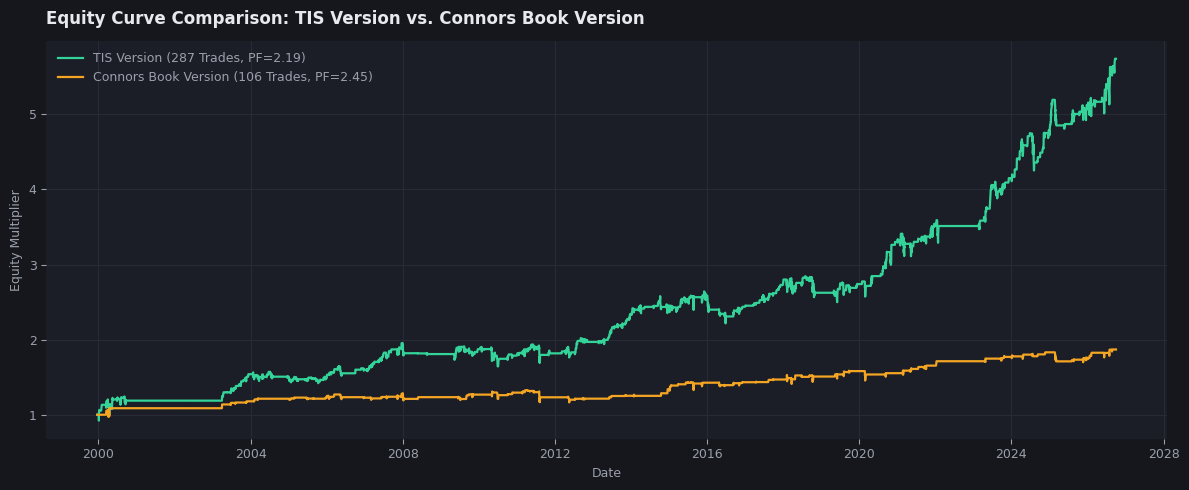

In [5]:
# Connors Original Book Rules: RSI(2) <= 5, Exit on Close > MA(5)
trades_connors = eng.run_rsi2_backtest(df, rsi_thr=5.0, sma_len=200, exit_mode="ma5", slip_pct_per_side=0.05)

m_tis = compute_metrics(trades_all, 1.0, 0.0)
m_con = compute_metrics(trades_connors, 1.0, 0.0)

ret_tis = eng.daily_returns(df, trades_all, "capital")
ret_con = eng.daily_returns(df, trades_connors, "capital")
eq_tis = (1 + ret_tis).cumprod()
eq_con = (1 + ret_con).cumprod()

comp_variants = pd.DataFrame([
    {
        'Strategy Variant': 'TIS Version (RSI<15, 2 Green Candles Exit)',
        'Trades': m_tis['num_trades'],
        'Win Rate': f"{m_tis['win_rate']:.1f}%",
        'Profit Factor': f"{m_tis['profit_factor']:.3f}",
        'Expectancy': f"{m_tis['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_all['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_tis):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_tis)*100:.2f}%"
    },
    {
        'Strategy Variant': 'Connors Book Version (RSI<5, Close>MA5 Exit)',
        'Trades': m_con['num_trades'],
        'Win Rate': f"{m_con['win_rate']:.1f}%",
        'Profit Factor': f"{m_con['profit_factor']:.3f}",
        'Expectancy': f"{m_con['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_connors['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_con):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_con)*100:.2f}%"
    }
])

print("=" * 80)
print("VARIANT COMPARISON: TIS RULES VS. CONNORS BOOK RULES")
print("=" * 80)
display(comp_variants)

# Visual Comparison of Variants
fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26')
ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

ax.plot(df.index, eq_tis, color='#34d399', lw=1.6, label='TIS Version (287 Trades, PF=2.19)')
ax.plot(df.index, eq_con, color='#f5a524', lw=1.6, label='Connors Book Version (106 Trades, PF=2.45)')
ax.set_title('Equity Curve Comparison: TIS Version vs. Connors Book Version', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left', pad=12)
ax.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 7. SUMMARY OF HYPOTHESIS & NEXT STEPS

### Key Findings:
1. **Hypothesis Confirmed**: Buying short-term pullbacks (`RSI(2) < 15`) in an uptrend (`Close > SMA(200)`) yields an exceptionally strong edge on QQQ with a 70.7% win rate and Profit Factor of 2.189 across 27+ years.
2. **Robustness of ATR Sizing**: The 1% risk ATR(14)x2 sizing model reduces maximum drawdown to just **-6.68%** over the entire 1999–2026 span, providing a stable institutional risk profile.
3. **Reproducibility**: Our implementation exactly replicates the TIS reference benchmark (194 IS trades with PF=1.990; 93 OOS trades with PF=2.681).
4. **Next Step**: Proceed to `02_RSI2_Optimization.ipynb` to evaluate parameter sensitivity and verify that `(15, 200)` sits on a broad, stable parameter plateau on in-sample data.